# RAG vs GraphRAG vs Agent Memory

> **Not every LLM context problem is a RAG problem.**

This notebook builds three ways of giving an LLM context on **one shared storyline**, then puts them head to head:

| | Asks | Built with |
|---|---|---|
| **1. RAG** | *What text is similar?* | LangChain + Gemini embeddings + in-memory vector store |
| **2. GraphRAG** | *What facts are connected?* | LangChain `LLMGraphTransformer` + Neo4j (text-to-Cypher and hybrid graph retrieval) |
| **3. Agent Memory** | *What did this user tell me before, and is it still true?* | **Graphiti (Zep)** temporal knowledge graph on Neo4j |

Finally, a **LangGraph agent** combines all three, and an LLM-as-judge scores every system on lookup, multi-hop, personal and temporal questions.

### Why a *temporal* knowledge graph for memory?
A Temporal Knowledge Graph (TKG) stores not only **what** the agent knows, but also:
- **when a fact was true**: `valid_at` / `invalid_at` (event time)
- **when the agent learned it**: `created_at` / `expired_at` (ingestion time)
- **how it changed**: contradicting facts are *invalidated*, not deleted, so history stays queryable.

That bi-temporal model is what turns a knowledge graph into real, persistent agent memory.

## 0. Setup

1. `pip install -r requirements.txt` (or run the next cell).
2. Copy `.env.example` to `.env` and fill in `GOOGLE_API_KEY`, `NEO4J_PASSWORD` (and `GROQ_API_KEY` if you set `USE_GROQ = True`).

All three systems share **one Neo4j AuraDB database**. They are kept apart by label: LangChain GraphRAG writes `__Entity__` / `Document` nodes, and Graphiti writes `Entity` / `Episodic` nodes scoped by `group_id`. The cleanup helpers below only ever touch the demo's own data.

In [ ]:
# %pip install -q -r requirements.txt

In [1]:
import os
import time
import asyncio
import warnings
from datetime import datetime, timezone
from typing import Literal, TypedDict

import pandas as pd
from dotenv import load_dotenv

warnings.filterwarnings("ignore")
load_dotenv()

# Graphiti reads SEMAPHORE_LIMIT at import time; a low value keeps the Gemini free tier happy.
os.environ.setdefault("SEMAPHORE_LIMIT", "4")

missing = [k for k in ("GOOGLE_API_KEY", "NEO4J_URI", "NEO4J_USERNAME", "NEO4J_PASSWORD") if not os.getenv(k)]
assert not missing, f"Missing in .env: {missing}"
print("Environment loaded (keys not printed).")

Environment loaded (keys not printed).


In [2]:
# ---- Config: change models here ----
LLM_MODEL   = "gemini-3.5-flash-lite"        # generation + extraction
SMALL_MODEL = "gemini-3.5-flash-lite"   # Graphiti small tasks + reranking
EMBED_MODEL = "gemini-embedding-001"

USE_GROQ   = False                      # True -> answers generated by Groq (fast); extraction stays on Gemini
GROQ_MODEL = "llama-3.3-70b-versatile"

GOOGLE_API_KEY = os.environ["GOOGLE_API_KEY"]
NEO4J_URI      = os.environ["NEO4J_URI"]
NEO4J_USERNAME = os.environ["NEO4J_USERNAME"]
NEO4J_PASSWORD = os.environ["NEO4J_PASSWORD"]
NEO4J_DATABASE = os.getenv("NEO4J_DATABASE", "26993cd0")

USER_ID = "user_alex"                   # Graphiti group_id = one memory graph per user

In [3]:
# from dotenv import load_dotenv
# import os

# load_dotenv(override=True)

# NEO4J_DATABASE = os.getenv("NEO4J_DATABASE", "neo4j")
print(NEO4J_DATABASE)

26993cd0


In [4]:
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings

llm = ChatGoogleGenerativeAI(model=LLM_MODEL, temperature=0, max_retries=6)
embeddings = GoogleGenerativeAIEmbeddings(model=f"models/{EMBED_MODEL}")

if USE_GROQ:
    from langchain_groq import ChatGroq
    answer_llm = ChatGroq(model=GROQ_MODEL, temperature=0, max_retries=6)
else:
    answer_llm = llm

print(llm.invoke("Reply with exactly: Gemini OK").content)

[{'type': 'text', 'text': 'Gemini OK', 'extras': {'signature': 'EmAKXgFpFH0TmXoOVLiCZItCxazaFLUmqd8lGN7oEeM5R+mgNA63o5if4VimmiyGRYonF/6Co6br8DXC/xu3U/xH3rvnH1Rlr3mOihnmPbwd+9FmPKfGMRiYMbokPASipUI='}}]


In [9]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USERNAME, NEO4J_PASSWORD))
driver.verify_connectivity()


def cypher(query, **params):
    # Run Cypher against the demo database and return a DataFrame.
    records, _, keys = driver.execute_query(query, params, database_=NEO4J_DATABASE)
    rows = [{k: (v.to_native() if hasattr(v, "to_native") else v) for k, v in r.items()} for r in records]
    return pd.DataFrame(rows, columns=keys)


def label_counts():
    return cypher("MATCH (n) UNWIND labels(n) AS label RETURN label, count(*) AS nodes ORDER BY nodes DESC")


def clear_graphrag():
    # Delete only LangChain GraphRAG data (__Entity__ + Document nodes).
    cypher("MATCH (n) WHERE n:__Entity__ OR n:Document DETACH DELETE n")


print("Connected to Neo4j:", NEO4J_URI)
label_counts()

Connected to Neo4j: neo4j+ssc://26993cd0.databases.neo4j.io


,label,nodes


In [10]:
print("URI:", NEO4J_URI)
print("Database:", NEO4J_DATABASE)

driver.verify_connectivity()

with driver.session(database=NEO4J_DATABASE) as session:
    result = session.run("RETURN 1 AS test")
    print(result.single()["test"])

URI: neo4j+ssc://26993cd0.databases.neo4j.io
Database: 26993cd0
1


In [7]:
print("NEO4J_URI:", NEO4J_URI)
print("NEO4J_DATABASE:", repr(NEO4J_DATABASE))
print("NEO4J_USERNAME:", NEO4J_USERNAME)

NEO4J_URI: neo4j+ssc://26993cd0.databases.neo4j.io
NEO4J_DATABASE: '26993cd0'
NEO4J_USERNAME: 26993cd0


## 1. Shared dataset: the README storyline

- **`DOCS`**: a small company knowledge base. Multi-hop facts are *deliberately split* across documents (Lisa → Tech Summit in one doc, Tech Summit → Barcelona in another), and there's a Barcelona distractor.
- **`CHAT_SESSIONS`**: what a user (Alex) tells the assistant over four months, including facts that **change** (moves city, stops running).
- **`EVAL_QUESTIONS`**: tagged *lookup*, *multi-hop*, *personal*, *temporal*, with reference answers for the judge.

In [11]:
from langchain_core.documents import Document

DOCS = [
    Document(page_content="Acme Store return policy: customers can return any unused item within 30 days of delivery "
                          "for a full refund. Electronics must be returned within 14 days. Refunds are issued to the "
                          "original payment method within 5 business days.", metadata={"source": "return_policy"}),
    Document(page_content="Lisa Chen is a senior machine learning engineer at Acme Corp. She leads the search "
                          "infrastructure team.", metadata={"source": "people/lisa"}),
    Document(page_content="Lisa Chen attended the Global Tech Summit, where she gave a keynote on vector databases "
                          "and ran a hands-on workshop on hybrid search.", metadata={"source": "events/lisa_summit"}),
    Document(page_content="The Global Tech Summit 2026 was held in Barcelona, Spain, from May 12 to May 14 and drew "
                          "more than 8,000 attendees.", metadata={"source": "events/summit"}),
    Document(page_content="Barcelona is famous for the Sagrada Familia and its beaches. The city also hosts the "
                          "Barcelona Marketing Expo every October.", metadata={"source": "travel/barcelona"}),
    Document(page_content="Marco Rossi, the CTO of Acme Corp, spoke at the Global Tech Summit about autonomous AI "
                          "agents.", metadata={"source": "people/marco"}),
    Document(page_content="AcmeSearch is Acme's flagship hybrid search engine. It was built by the search "
                          "infrastructure team.", metadata={"source": "products/acmesearch"}),
    Document(page_content="Acme Corp is headquartered in Berlin and has offices in Lisbon and Toronto.",
             metadata={"source": "company"}),
]


def ts(s):
    return datetime.fromisoformat(s).replace(tzinfo=timezone.utc)


# (session, timestamp, user message)
CHAT_SESSIONS = [
    (1, ts("2026-02-10T09:00"), "Hi! I'm Alex. I love hiking and I go trail running most weekends."),
    (1, ts("2026-02-10T09:02"), "I live in Madrid, in the Chamberi neighbourhood."),
    (2, ts("2026-03-22T18:30"), "I just got back from a hiking trip in the Sierra de Guadarrama near Madrid."),
    (2, ts("2026-03-22T18:33"), "By the way, I'm vegetarian."),
    (3, ts("2026-06-15T08:15"), "Big news: I moved from Madrid to Lisbon this month for a new job at Acme."),
    (3, ts("2026-06-15T08:20"), "I've had to stop trail running because of a knee injury, but I still enjoy easy hikes."),
]

EVAL_QUESTIONS = [
    ("lookup",    "How long do I have to return electronics?",               "14 days."),
    ("lookup",    "How quickly are refunds issued?",                         "Within 5 business days, to the original payment method."),
    ("multi-hop", "What did Lisa Chen do in Barcelona?",                     "At the Global Tech Summit 2026 in Barcelona she gave a keynote on vector databases and ran a workshop on hybrid search."),
    ("multi-hop", "Which Acme people spoke at the event held in Barcelona?", "Lisa Chen and Marco Rossi (Global Tech Summit)."),
    ("multi-hop", "Who leads the team that built AcmeSearch?",               "Lisa Chen (search infrastructure team)."),
    ("personal",  "What outdoor activities do I enjoy?",                     "Hiking (easy hikes); trail running was stopped due to a knee injury."),
    ("personal",  "Do I have any dietary restrictions?",                     "Yes, vegetarian."),
    ("temporal",  "Which city do I live in now?",                            "Lisbon."),
    ("temporal",  "Where was I living in April 2026?",                       "Madrid."),
]
print(len(DOCS), "docs |", len(CHAT_SESSIONS), "chat turns |", len(EVAL_QUESTIONS), "eval questions")

8 docs | 6 chat turns | 9 eval questions


## 2. Classic RAG: *find similar text*

Embed chunks, embed the query, return the top-k most similar chunks, and let the LLM answer from them.

In [12]:
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_text_splitters import RecursiveCharacterTextSplitter

chunks = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=0).split_documents(DOCS)
vector_store = InMemoryVectorStore.from_documents(chunks, embeddings)
retriever = vector_store.as_retriever(search_kwargs={"k": 2})

ANSWER_PROMPT = ChatPromptTemplate.from_template(
    "Answer the question using ONLY the context. If the context is not enough, say \"I don't know\".\n\n"
    "Context:\n{context}\n\nQuestion: {question}"
)
answer_chain = ANSWER_PROMPT | answer_llm | StrOutputParser()


def rag_retrieve(question):
    return "\n".join(f"- {d.page_content}" for d in retriever.invoke(question))


def rag_answer(question):
    context = rag_retrieve(question)
    return answer_chain.invoke({"context": context, "question": question}), context


print(f"{len(chunks)} chunks indexed")

8 chunks indexed


In [13]:
for q in ["What is the return policy for electronics?", "What did Lisa Chen do in Barcelona?"]:
    answer, context = rag_answer(q)
    print(f"Q: {q}\nRetrieved:\n{context}\nA: {answer}\n" + "-" * 80)

Q: What is the return policy for electronics?
Retrieved:
- Acme Store return policy: customers can return any unused item within 30 days of delivery for a full refund. Electronics must be returned within 14 days. Refunds are issued to the original payment method within 5 business days.
- Acme Corp is headquartered in Berlin and has offices in Lisbon and Toronto.
A: Electronics must be returned within 14 days.
--------------------------------------------------------------------------------
Q: What did Lisa Chen do in Barcelona?
Retrieved:
- Lisa Chen attended the Global Tech Summit, where she gave a keynote on vector databases and ran a hands-on workshop on hybrid search.
- Lisa Chen is a senior machine learning engineer at Acme Corp. She leads the search infrastructure team.
A: I don't know
--------------------------------------------------------------------------------


**What to notice:** the return-policy question is a perfect fit, because the answer lives in one chunk that looks like the question.

For *"What did Lisa do in Barcelona?"* the facts are split: the chunk that mentions Lisa never says "Barcelona", and the chunk that says "Barcelona" never mentions Lisa. Similarity search usually returns the Summit chunk plus the **Barcelona travel distractor**, so the answer is incomplete or "I don't know". Results can vary a little between runs; raise `k` and it may get lucky, but it is not *reasoning* over the connection.

## 3. GraphRAG: *follow connected facts*

`LLMGraphTransformer` asks Gemini to extract entities and relationships from each document. Those become nodes and edges in Neo4j, with each source chunk kept as a `Document` node linked by `MENTIONS`.

Retrieval then **walks the graph** in two ways:
1. **Text-to-Cypher** (`GraphCypherQAChain`): the LLM writes a Cypher query.
2. **Hybrid retriever**: find the entities in the question, expand their 1–2 hop neighbourhood, and add vector-similar chunks.

In [14]:
from langchain_experimental.graph_transformers import LLMGraphTransformer
from langchain_neo4j import Neo4jGraph

graph = Neo4jGraph(url=NEO4J_URI, username=NEO4J_USERNAME, password=NEO4J_PASSWORD,
                   database=NEO4J_DATABASE, refresh_schema=False)

transformer = LLMGraphTransformer(
    llm=llm,
    allowed_nodes=["Person", "Organization", "Event", "City", "Country", "Product", "Team", "Topic", "Policy"],
    allowed_relationships=["WORKS_AT", "LEADS", "MEMBER_OF", "ATTENDED", "SPOKE_AT", "PRESENTED_ON",
                           "HELD_IN", "LOCATED_IN", "BUILT", "HEADQUARTERED_IN", "HAS_OFFICE_IN", "HAS_POLICY"],
    strict_mode=False,
)

clear_graphrag()  # idempotent re-runs
graph_docs = transformer.convert_to_graph_documents(DOCS)
graph.add_graph_documents(graph_docs, baseEntityLabel=True, include_source=True)

for gd in graph_docs:
    for r in gd.relationships:
        print(f"{r.source.id} -[{r.type}]-> {r.target.id}")

Acme Store -[HAS_POLICY]-> Return Policy
Lisa Chen -[WORKS_AT]-> Acme Corp
Lisa Chen -[LEADS]-> Search Infrastructure Team
Lisa Chen -[ATTENDED]-> Global Tech Summit
Lisa Chen -[SPOKE_AT]-> Global Tech Summit
Lisa Chen -[PRESENTED_ON]-> Vector Databases
Lisa Chen -[PRESENTED_ON]-> Hybrid Search
Global Tech Summit 2026 -[HELD_IN]-> Barcelona
Barcelona -[LOCATED_IN]-> Spain
Sagrada Familia -[LOCATED_IN]-> Barcelona
Barcelona Marketing Expo -[HELD_IN]-> Barcelona
Marco Rossi -[WORKS_AT]-> Acme Corp
Marco Rossi -[SPOKE_AT]-> Global Tech Summit
Marco Rossi -[PRESENTED_ON]-> Autonomous Ai Agents
Acmesearch -[MEMBER_OF]-> Acme
Search Infrastructure Team -[BUILT]-> Acmesearch
Acme Corp -[HEADQUARTERED_IN]-> Berlin
Acme Corp -[HAS_OFFICE_IN]-> Lisbon
Acme Corp -[HAS_OFFICE_IN]-> Toronto


In [15]:
# Inspect the graph (entity-to-entity edges only)
cypher('''
MATCH (a:__Entity__)-[r]->(b:__Entity__)
RETURN labels(a)[0] AS from_type, a.id AS source, type(r) AS rel, b.id AS target, labels(b)[0] AS to_type
ORDER BY source
''')

,from_type,source,rel,target,to_type
0,__Entity__,Acme Corp,HEADQUARTERED_IN,Berlin,__Entity__
1,__Entity__,Acme Corp,HAS_OFFICE_IN,Lisbon,__Entity__
2,__Entity__,Acme Corp,HAS_OFFICE_IN,Toronto,__Entity__
3,__Entity__,Acme Store,HAS_POLICY,Return Policy,__Entity__
4,__Entity__,Acmesearch,MEMBER_OF,Acme,__Entity__
5,__Entity__,Barcelona,LOCATED_IN,Spain,__Entity__
6,__Entity__,Barcelona Marketing Expo,HELD_IN,Barcelona,__Entity__
7,__Entity__,Global Tech Summit 2026,HELD_IN,Barcelona,__Entity__
8,__Entity__,Lisa Chen,WORKS_AT,Acme Corp,__Entity__
9,__Entity__,Lisa Chen,LEADS,Search Infrastructure Team,__Entity__


In [16]:
# Optional: interactive graph view (pip install yfiles_jupyter_graphs)
try:
    from yfiles_jupyter_graphs import GraphWidget
    records, _, _ = driver.execute_query(
        "MATCH p=(a:__Entity__)-[r]->(b:__Entity__) RETURN p", database_=NEO4J_DATABASE)
    w = GraphWidget(graph=records)
    w.node_label_mapping = "id"
    display(w)
except ImportError:
    print("yfiles_jupyter_graphs not installed; skipping visual graph.")

NotImplementedError: Could not find a graph importer factory for type <class 'list'>

In [17]:
from yfiles_jupyter_graphs import GraphWidget
from IPython.display import display

# Fetch entity-to-entity relationships
records, _, _ = driver.execute_query(
    """
    MATCH p = (a:__Entity__)-[r]->(b:__Entity__)
    RETURN p
    """,
    database_=NEO4J_DATABASE,
)

# Convert Neo4j paths into yFiles nodes and edges
nodes = {}
edges = []

for record in records:
    path = record["p"]

    for node in path.nodes:
        node_id = str(node.element_id)

        nodes[node_id] = {
            "id": node_id,
            "label": node.get("name", node_id),
            "properties": dict(node),
        }

    for rel in path.relationships:
        source = str(rel.start_node.element_id)
        target = str(rel.end_node.element_id)

        edges.append({
            "id": str(rel.element_id),
            "start": source,
            "end": target,
            "label": rel.type,
        })

# Initialize the widget with supported node and edge data
w = GraphWidget()
w.nodes = list(nodes.values())
w.edges = edges
w.node_label_mapping = "label"
w.edge_label_mapping = "label"

display(w)

GraphWidget(layout=Layout(height='700px', width='100%'))

### 3a. Text-to-Cypher

The schema passed to the LLM excludes Graphiti's labels (`Entity`, `Episodic`, …) so the LLM only sees the GraphRAG part of the shared database.

In [18]:
from langchain_neo4j import GraphCypherQAChain

graph.refresh_schema()
GRAPHITI_TYPES = ["Entity", "Episodic", "Community", "Saga", "Document",
                  "RELATES_TO", "MENTIONS", "HAS_MEMBER", "HAS_EPISODE", "NEXT_EPISODE"]

cypher_chain = GraphCypherQAChain.from_llm(
    llm=llm, graph=graph, exclude_types=GRAPHITI_TYPES,
    validate_cypher=True, allow_dangerous_requests=True,  # read-only demo DB; the LLM writes the Cypher
    return_intermediate_steps=True, verbose=False,
)

res = cypher_chain.invoke({"query": "What did Lisa Chen do in Barcelona?"})
print("Generated Cypher:\n", res["intermediate_steps"][0]["query"])
print("Answer:", res["result"])

Generated Cypher:
 MATCH (p:Person {id: 'Lisa Chen'})-[:ATTENDED|SPOKE_AT|PRESENTED_ON]->(e:Event)-[:HELD_IN]->(c:City {id: 'Barcelona'})
RETURN e, labels(e)
Answer: I don't know the answer.


### 3b. Hybrid graph retriever: entities → neighbourhood + vector chunks

Text-to-Cypher is brittle when the LLM guesses the wrong relationship name. The hybrid retriever is more robust: extract entity names, fuzzy-match them with a full-text index, pull every fact within 2 hops, and add the most similar source chunks.

In [19]:
import re
from pydantic import BaseModel, Field
from langchain_neo4j import Neo4jVector

cypher("CREATE FULLTEXT INDEX graphrag_entity_ids IF NOT EXISTS FOR (e:__Entity__) ON EACH [e.id]")

chunk_index = Neo4jVector.from_existing_graph(
    embeddings, url=NEO4J_URI, username=NEO4J_USERNAME, password=NEO4J_PASSWORD, database=NEO4J_DATABASE,
    index_name="graphrag_chunks", node_label="Document",
    text_node_properties=["text"], embedding_node_property="embedding",
)


class Entities(BaseModel):
    names: list[str] = Field(description="People, organisations, events, places, products or teams in the text")


entity_extractor = llm.with_structured_output(Entities)


def fulltext_query(name):
    words = [w for w in re.sub(r"[^\w\s]", " ", name).split() if w]
    return " AND ".join(f"{w}~1" for w in words)


def graph_retrieve(question, hops=2):
    names = entity_extractor.invoke(f"Extract the entities mentioned in: {question}").names
    facts = set()
    for name in names:
        if not fulltext_query(name):
            continue
        df = cypher(f'''
            CALL db.index.fulltext.queryNodes('graphrag_entity_ids', $q, {{limit: 2}}) YIELD node
            MATCH path = (node)-[rels*1..{hops}]-(:__Entity__)
            WHERE all(x IN rels WHERE type(x) <> 'MENTIONS')
            UNWIND relationships(path) AS r
            RETURN DISTINCT startNode(r).id + ' -' + type(r) + '-> ' + endNode(r).id AS fact
            LIMIT 60''', q=fulltext_query(name))
        facts.update(df["fact"].tolist() if not df.empty else [])
    chunks_txt = [d.page_content for d in chunk_index.similarity_search(question, k=2)]
    return ("Graph facts:\n" + "\n".join(f"- {f}" for f in sorted(facts)) +
            "\n\nSource chunks:\n" + "\n".join(f"- {c}" for c in chunks_txt))


def graphrag_answer(question):
    context = graph_retrieve(question)
    return answer_chain.invoke({"context": context, "question": question}), context


answer, context = graphrag_answer("What did Lisa Chen do in Barcelona?")
print(context, "\n\nA:", answer)

Graph facts:
- Acme Corp -HAS_OFFICE_IN-> Lisbon
- Acme Corp -HAS_OFFICE_IN-> Toronto
- Acme Corp -HEADQUARTERED_IN-> Berlin
- Barcelona -LOCATED_IN-> Spain
- Barcelona Marketing Expo -HELD_IN-> Barcelona
- Global Tech Summit 2026 -HELD_IN-> Barcelona
- Lisa Chen -ATTENDED-> Global Tech Summit
- Lisa Chen -LEADS-> Search Infrastructure Team
- Lisa Chen -PRESENTED_ON-> Hybrid Search
- Lisa Chen -PRESENTED_ON-> Vector Databases
- Lisa Chen -SPOKE_AT-> Global Tech Summit
- Lisa Chen -WORKS_AT-> Acme Corp
- Marco Rossi -SPOKE_AT-> Global Tech Summit
- Marco Rossi -WORKS_AT-> Acme Corp
- Sagrada Familia -LOCATED_IN-> Barcelona
- Search Infrastructure Team -BUILT-> Acmesearch

Source chunks:
- 
text: Lisa Chen attended the Global Tech Summit, where she gave a keynote on vector databases and ran a hands-on workshop on hybrid search.
- 
text: Barcelona is famous for the Sagrada Familia and its beaches. The city also hosts the Barcelona Marketing Expo every October. 

A: I don't know.


In [20]:
answer, context = graphrag_answer("Which city do I live in now?")
print("A:", answer)

A: I don't know


**What to notice:** the graph path *Lisa → ATTENDED/SPOKE_AT → Global Tech Summit → HELD_IN → Barcelona* answers the multi-hop question, even though no single document contains it.

The limit is just as clear: the graph is a **static knowledge base**. It has no idea who "I" am, and no notion of *time*. It can't tell you what was true in April versus now.

## 4. Agent Memory: Graphiti temporal knowledge graph

[Graphiti](https://github.com/getzep/graphiti) (the engine behind Zep) ingests **episodes** (chat turns, events, JSON) incrementally. For each episode it:
1. extracts entities and resolves them against existing nodes (no duplicate "Madrid" nodes),
2. extracts **facts as edges** (`RELATES_TO`), each with `valid_at` / `invalid_at` (when it was true in the world),
3. stamps `created_at` (when the agent learned it), and
4. **detects contradictions**: when a new fact supersedes an old one, the old edge gets `invalid_at` / `expired_at` set. It is *not deleted*.

Everything is partitioned by `group_id`, so each user gets a private memory graph.

In [21]:
from graphiti_core import Graphiti
from graphiti_core.nodes import EpisodeType
from graphiti_core.driver.neo4j_driver import Neo4jDriver
from graphiti_core.llm_client.config import LLMConfig
from graphiti_core.llm_client.gemini_client import GeminiClient
from graphiti_core.embedder.gemini import GeminiEmbedder, GeminiEmbedderConfig
from graphiti_core.cross_encoder.gemini_reranker_client import GeminiRerankerClient
from graphiti_core.search.search_filters import SearchFilters, DateFilter, ComparisonOperator
from graphiti_core.utils.maintenance.graph_data_operations import clear_data

graphiti = Graphiti(
    graph_driver=Neo4jDriver(uri=NEO4J_URI, user=NEO4J_USERNAME, password=NEO4J_PASSWORD, database=NEO4J_DATABASE),
    llm_client=GeminiClient(config=LLMConfig(api_key=GOOGLE_API_KEY, model=LLM_MODEL, small_model=SMALL_MODEL)),
    embedder=GeminiEmbedder(config=GeminiEmbedderConfig(api_key=GOOGLE_API_KEY, embedding_model=EMBED_MODEL)),
    cross_encoder=GeminiRerankerClient(config=LLMConfig(api_key=GOOGLE_API_KEY, model=SMALL_MODEL)),
)
await graphiti.build_indices_and_constraints()


async def clear_memory(group_id=USER_ID):
    # Delete only this user's Graphiti memory graph.
    await clear_data(graphiti.driver, group_ids=[group_id])


print("Graphiti ready")

Error executing Neo4j query: {neo4j_code: Neo.ClientError.Schema.EquivalentSchemaRuleAlreadyExists} {message: An equivalent index already exists, 'Index( id=6, name='community_uuid', type='RANGE', schema=(:Community {uuid}), indexProvider='range-1.0' )'.} {gql_status: 22N70} {gql_status_description: error: data exception - equivalent index already exists. An equivalent index already exists: 'community_uuid'}
CREATE INDEX community_uuid IF NOT EXISTS FOR (n:Community) ON (n.uuid)
parameter keys: []
Error executing Neo4j query: {neo4j_code: Neo.ClientError.Schema.EquivalentSchemaRuleAlreadyExists} {message: An equivalent index already exists, 'Index( id=8, name='episode_uuid', type='RANGE', schema=(:Episodic {uuid}), indexProvider='range-1.0' )'.} {gql_status: 22N70} {gql_status_description: error: data exception - equivalent index already exists. An equivalent index already exists: 'episode_uuid'}
CREATE INDEX episode_uuid IF NOT EXISTS FOR (n:Episodic) ON (n.uuid)
parameter keys: []
Er

Graphiti ready


### 4a. Custom entity types (structured memory)

Pydantic models tell Graphiti what kinds of things are worth remembering about a user. The docstring is the extraction instruction.

In [22]:
class Preference(BaseModel):
    '''A user's like, dislike, habit, hobby or dietary choice.'''
    category: str | None = Field(None, description="e.g. activity, food, travel")


class Location(BaseModel):
    '''A city, neighbourhood, region or country.'''
    kind: str | None = Field(None, description="city, neighbourhood, region or country")


class Organization(BaseModel):
    '''A company or employer.'''
    industry: str | None = Field(None, description="industry, if mentioned")


ENTITY_TYPES = {"Preference": Preference, "Location": Location, "Organization": Organization}

### 4b. Ingest the chat sessions as episodes

Each turn is added with its **real timestamp** as `reference_time`. That's how Graphiti resolves "this month" to June 2026 and knows *when* each fact became true.

In [23]:
async def remember(text, when, name, role="user", description="chat"):
    # add_episode with simple retry/backoff for free-tier rate limits.
    for attempt in range(5):
        try:
            return await graphiti.add_episode(
                name=name, episode_body=f"{role}: {text}", source=EpisodeType.message,
                source_description=description, reference_time=when,
                group_id=USER_ID, entity_types=ENTITY_TYPES,
            )
        except Exception as e:
            wait = 10 * (attempt + 1)
            print(f"  retry in {wait}s ({type(e).__name__}: {str(e)[:80]})")
            await asyncio.sleep(wait)
    raise RuntimeError("add_episode failed after retries")


await clear_memory()  # idempotent re-runs
for i, (session, when, text) in enumerate(CHAT_SESSIONS):
    t0 = time.perf_counter()
    result = await remember(text, when, name=f"session{session}-turn{i}", description=f"chat session {session}")
    print(f"[{when:%Y-%m-%d}] {text[:60]:<60} -> +{len(result.edges)} facts ({time.perf_counter() - t0:.1f}s)")

Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `entity_edges` does not exist in database `26993cd0`. Verify that the spelling is correct.', position=<SummaryInputPosition line=17, column=7, offset=473>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 473, 'line': 17, 'column': 7}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\n                                    MATCH (e:Episodic)\n                                    WHERE e.valid_at <= $reference_time\n                                    \nAND e.group_id IN $group_ids\nAND e.source = $source\n        RETURN\n        \n    e.uuid AS uuid,\n    e.name AS name,\n    e.group_id

[2026-02-10] Hi! I'm Alex. I love hiking and I go trail running most week -> +2 facts (26.2s)


Error in generating LLM response: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Retrying after application error (attempt 1/2): 


[2026-02-10] I live in Madrid, in the Chamberi neighbourhood.             -> +1 facts (42.5s)
[2026-03-22] I just got back from a hiking trip in the Sierra de Guadarra -> +3 facts (62.7s)
[2026-03-22] By the way, I'm vegetarian.                                  -> +1 facts (36.3s)
[2026-06-15] Big news: I moved from Madrid to Lisbon this month for a new -> +3 facts (46.9s)
[2026-06-15] I've had to stop trail running because of a knee injury, but -> +3 facts (36.5s)


### 4c. The temporal view: facts with their validity windows

Look for the *lives in Madrid* fact: after the session-3 episode it should have **`invalid_at` ≈ June 2026** and an `expired_at` timestamp, while *lives in Lisbon* is valid from June. The same goes for trail running. Nothing was deleted.

In [24]:
def memory_timeline(group_id=USER_ID):
    df = cypher('''
        MATCH (a:Entity)-[r:RELATES_TO]->(b:Entity) WHERE r.group_id = $g
        RETURN r.fact AS fact, r.valid_at AS valid_at, r.invalid_at AS invalid_at,
               r.created_at AS learned_at, r.expired_at AS expired_at
        ORDER BY coalesce(r.valid_at, r.created_at)''', g=group_id)
    for col in ["valid_at", "invalid_at", "learned_at", "expired_at"]:
        df[col] = pd.to_datetime(df[col], utc=True, errors="coerce").dt.strftime("%Y-%m-%d").fillna("")
    df["status"] = ["superseded" if inv or exp else "current" for inv, exp in zip(df.invalid_at, df.expired_at)]
    return df


pd.set_option("display.max_colwidth", 90)
memory_timeline()

,fact,valid_at,invalid_at,learned_at,expired_at,status
0,Alex loves hiking,2026-02-10,,2026-10-18,,current
1,Alex goes trail running most weekends,2026-02-10,2026-06-15,2026-10-18,2026-10-18,superseded
2,The Chamberi neighbourhood is located in Madrid,2026-02-10,,2026-10-18,,current
3,user went on a hiking trip,2026-03-22,,2026-10-18,,current
4,hiking trip took place in Sierra de Guadarrama,2026-03-22,,2026-10-18,,current
5,Sierra de Guadarrama is located near Madrid,2026-03-22,,2026-10-18,,current
6,Alex follows a vegetarian diet.,2026-03-22,,2026-10-18,,current
7,Alex moved away from Madrid this month,2026-06-15,2026-06-15,2026-10-18,2026-10-18,superseded
8,Alex moved to Lisbon this month,2026-06-15,,2026-10-18,,current
9,Alex started a new job at Acme this month,2026-06-15,,2026-10-18,,current


In [25]:
# Extracted entities and their (custom) types
cypher('''
MATCH (n:Entity) WHERE n.group_id = $g
RETURN n.name AS entity, [l IN labels(n) WHERE l <> 'Entity'] AS types, n.summary AS summary
ORDER BY entity''', g=USER_ID)

,entity,types,summary
0,Acme,[Organization],Alex started a new job at Acme this month
1,Alex,[],Alex loves hiking\nAlex goes trail running most weekends\nAlex follows a vegetarian di...
2,Chamberi neighbourhood,[Location],The Chamberi neighbourhood is located in Madrid
3,Lisbon,[Location],Alex moved to Lisbon this month
4,Madrid,[Location],The Chamberi neighbourhood is located in Madrid\nSierra de Guadarrama is located near ...
5,Sierra de Guadarrama,[Location],hiking trip took place in Sierra de Guadarrama\nSierra de Guadarrama is located near M...
6,hiking,[Preference],Alex loves hiking\nAlex still enjoys easy hikes
7,hiking trip,[],user went on a hiking trip\nhiking trip took place in Sierra de Guadarrama
8,trail running,[Preference],Alex goes trail running most weekends\nAlex had to stop trail running because of a kne...
9,user,[],user went on a hiking trip


### 4d. Searching memory: "now" vs "as of a date"

`graphiti.search()` is hybrid (BM25 + embeddings + graph distance, then reranked) and returns **fact edges** together with their temporal fields. `SearchFilters` lets us ask the memory a point-in-time question:

- **now**: `invalid_at IS NULL`
- **as of T**: `valid_at <= T AND (invalid_at > T OR invalid_at IS NULL)`

In [26]:
def current_filter():
    return SearchFilters(invalid_at=[[DateFilter(comparison_operator=ComparisonOperator.is_null)]])


def as_of_filter(t):
    return SearchFilters(
        valid_at=[[DateFilter(date=t, comparison_operator=ComparisonOperator.less_than_equal)]],
        invalid_at=[[DateFilter(date=t, comparison_operator=ComparisonOperator.greater_than)],
                    [DateFilter(comparison_operator=ComparisonOperator.is_null)]],
    )


def fmt_edges(edges):
    def d(x):
        return x.strftime("%Y-%m-%d") if x else "…"
    return "\n".join(f"- {e.fact}  [valid {d(e.valid_at)} → {d(e.invalid_at)}]" for e in edges) or "- (no memories)"


q = "Where does Alex live?"
print("ALL facts (history included):\n" + fmt_edges(await graphiti.search(q, group_ids=[USER_ID], num_results=6)))
print("\nCURRENT facts:\n" + fmt_edges(await graphiti.search(q, group_ids=[USER_ID], num_results=6, search_filter=current_filter())))
print("\nAS OF 2026-04-15:\n" + fmt_edges(await graphiti.search(q, group_ids=[USER_ID], num_results=6, search_filter=as_of_filter(ts("2026-04-15T00:00")))))

ALL facts (history included):
- Alex loves hiking  [valid 2026-02-10 → …]
- Alex moved away from Madrid this month  [valid 2026-06-15 → 2026-06-15]
- Alex moved to Lisbon this month  [valid 2026-06-15 → …]
- Alex still enjoys easy hikes  [valid 2026-06-15 → …]
- Alex follows a vegetarian diet.  [valid 2026-03-22 → …]
- Alex goes trail running most weekends  [valid 2026-02-10 → 2026-06-15]

CURRENT facts:
- Alex loves hiking  [valid 2026-02-10 → …]
- Alex moved to Lisbon this month  [valid 2026-06-15 → …]
- Alex follows a vegetarian diet.  [valid 2026-03-22 → …]
- Alex still enjoys easy hikes  [valid 2026-06-15 → …]
- Alex started a new job at Acme this month  [valid 2026-06-15 → …]
- user went on a hiking trip  [valid 2026-03-22 → …]

AS OF 2026-04-15:
- Alex loves hiking  [valid 2026-02-10 → …]
- Alex follows a vegetarian diet.  [valid 2026-03-22 → …]
- Alex goes trail running most weekends  [valid 2026-02-10 → 2026-06-15]
- user went on a hiking trip  [valid 2026-03-22 → …]
- The Cha

In [27]:
MEMORY_PROMPT = ChatPromptTemplate.from_template(
    "You are a personal assistant. Today is {today}. Below are facts remembered about the user, each with the "
    "period it was valid ('…' = still valid). Prefer currently valid facts, and use the validity periods to answer "
    "questions about the past. If the memories don't answer it, say \"I don't know\".\n\n"
    "Memories:\n{memories}\n\nUser question: {question}"
)
memory_chain = MEMORY_PROMPT | answer_llm | StrOutputParser()
TODAY = ts("2026-10-18T12:00")


async def memory_retrieve(question, k=8):
    return fmt_edges(await graphiti.search(question, group_ids=[USER_ID], num_results=k))


async def memory_answer(question):
    memories = await memory_retrieve(question)
    return await memory_chain.ainvoke({"memories": memories, "question": question, "today": f"{TODAY:%Y-%m-%d}"}), memories


for q in ["Which city do I live in now?", "Where was I living in April 2026?", "Do I still go trail running?"]:
    answer, _ = await memory_answer(q)
    print(f"Q: {q}\nA: {answer}\n")

Q: Which city do I live in now?
A: Based on your memories, you live in Lisbon.

Q: Where was I living in April 2026?
A: Based on your memories, I don't know where you were living in April 2026.

Q: Do I still go trail running?
A: No, you had to stop trail running because of a knee injury.



**What to notice:** memory knows about *the user*, keeps **history** (Madrid is still there, marked as superseded), and answers *"where was I in April?"* correctly. Plain RAG over a chat log would see both "I live in Madrid" and "I moved to Lisbon" with no way to tell which is current.

## 5. LangGraph agent: memory + knowledge, written every turn

Production systems usually **combine** the three. This agent:

```
retrieve_memory ─▶ route ─▶ retrieve_knowledge (vector | graph | none) ─▶ generate ─▶ write_memory
```

- `retrieve_memory` reads the user's Graphiti graph before every turn.
- `route` picks vector RAG for single-document lookups, GraphRAG for relationship questions, or none for purely personal questions.
- `write_memory` stores the user turn (and the assistant reply) as new episodes, so the **next session starts with context instead of from zero**.

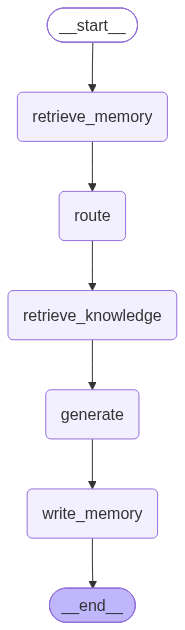

In [28]:
from langgraph.graph import StateGraph, START, END


class AgentState(TypedDict, total=False):
    question: str
    remember: bool
    memories: str
    route: str
    knowledge: str
    answer: str


class Route(BaseModel):
    source: Literal["vector", "graph", "none"] = Field(
        description="vector: answer is likely in one policy/FAQ document; "
                    "graph: needs relationships between people, events, places, products or teams; "
                    "none: only about the user personally")


router = llm.with_structured_output(Route)

AGENT_PROMPT = ChatPromptTemplate.from_template(
    "You are Acme's helpful assistant. Today is {today}.\n"
    "Facts remembered about this user (with validity periods; '…' = still valid):\n{memories}\n\n"
    "Company knowledge:\n{knowledge}\n\n"
    "Answer concisely, personalising with the user's CURRENT facts when relevant. "
    "If neither source answers the question, say so.\n\nUser: {question}"
)
agent_chain = AGENT_PROMPT | answer_llm | StrOutputParser()


async def retrieve_memory(state: AgentState):
    return {"memories": await memory_retrieve(state["question"])}


async def route(state: AgentState):
    return {"route": (await router.ainvoke(state["question"])).source}


async def retrieve_knowledge(state: AgentState):
    if state["route"] == "vector":
        return {"knowledge": rag_retrieve(state["question"])}
    if state["route"] == "graph":
        return {"knowledge": graph_retrieve(state["question"])}
    return {"knowledge": "(not needed)"}


async def generate(state: AgentState):
    answer = await agent_chain.ainvoke({**state, "today": f"{TODAY:%Y-%m-%d}"})
    return {"answer": answer}


async def write_memory(state: AgentState):
    if state.get("remember", True):
        now = datetime.now(timezone.utc)
        await remember(state["question"], now, name=f"agent-user-{now:%H%M%S}", description="agent chat")
        await remember(state["answer"], now, name=f"agent-assistant-{now:%H%M%S}", role="assistant",
                       description="agent chat")
    return {}


builder = StateGraph(AgentState)
for name, fn in [("retrieve_memory", retrieve_memory), ("route", route),
                 ("retrieve_knowledge", retrieve_knowledge), ("generate", generate), ("write_memory", write_memory)]:
    builder.add_node(name, fn)
builder.add_edge(START, "retrieve_memory")
builder.add_edge("retrieve_memory", "route")
builder.add_edge("route", "retrieve_knowledge")
builder.add_edge("retrieve_knowledge", "generate")
builder.add_edge("generate", "write_memory")
builder.add_edge("write_memory", END)
agent = builder.compile()

try:
    from IPython.display import Image, display
    display(Image(agent.get_graph().draw_mermaid_png()))
except Exception:
    print(agent.get_graph().draw_mermaid())

In [29]:
async def chat(question, remember=True):
    state = await agent.ainvoke({"question": question, "remember": remember})
    print(f"User: {question}\n  route={state['route']}\nAgent: {state['answer']}\n")
    return state


# A brand-new session: no chat history is passed in, only the persistent memory graph.
await chat("Can you recommend a weekend activity for me?")
await chat("I'm thinking of returning the headphones I bought 20 days ago. Can I?")
await chat("I've started learning to surf, by the way!")
_ = await chat("Given everything you know about me, what should I do this weekend?", remember=False)

User: Can you recommend a weekend activity for me?
  route=none
Agent: How about going for an easy hike around Lisbon? Since you moved there recently and still enjoy easy hikes, it's a great way to explore the area on the weekend!

User: I'm thinking of returning the headphones I bought 20 days ago. Can I?
  route=vector
Agent: No, you cannot. Electronics must be returned within 14 days of delivery for a full refund according to the Acme Store return policy.

User: I've started learning to surf, by the way!
  route=none
Agent: That sounds like a lot of fun, especially living in Lisbon! How are you enjoying it so far?

User: Given everything you know about me, what should I do this weekend?
  route=none
Agent: Since you recently started learning to surf and still enjoy easy hikes around Lisbon, you could hit the waves this weekend or check out a scenic, relaxing trail nearby!



**What to notice:**
- The weekend recommendation uses *Lisbon + easy hikes* (current facts), and doesn't suggest trail running or Madrid.
- The headphones question pulls the return policy (vector route): electronics have a 14-day window, so 20 days is too late.
- "I've started learning to surf" was written to memory, so the very next turn already uses it.

In [30]:
memory_timeline().tail(8)

,fact,valid_at,invalid_at,learned_at,expired_at,status
5,Sierra de Guadarrama is located near Madrid,2026-03-22,,2026-10-18,,current
6,Alex follows a vegetarian diet.,2026-03-22,,2026-10-18,,current
7,Alex moved away from Madrid this month,2026-06-15,2026-06-15,2026-10-18,2026-10-18,superseded
8,Alex moved to Lisbon this month,2026-06-15,,2026-10-18,,current
9,Alex started a new job at Acme this month,2026-06-15,,2026-10-18,,current
10,Alex still enjoys easy hikes,2026-06-15,,2026-10-18,,current
11,Alex had to stop trail running because of a knee injury,2026-06-15,2026-06-15,2026-10-18,2026-10-18,superseded
12,The user has started learning to surf,2026-10-18,,2026-10-18,,current


## 6. Head-to-head comparison

Every eval question goes through each system. Gemini, acting as judge, compares each answer to the reference: **correct = 1, partial = 0.5, wrong = 0**.

The agent runs with `remember=False` here so evaluation doesn't write to memory.

In [31]:
async def agent_answer(question):
    state = await agent.ainvoke({"question": question, "remember": False})
    return state["answer"], f"[route={state['route']}]\n{state['memories']}\n{state['knowledge']}"


SYSTEMS = {
    "RAG":          lambda q: asyncio.to_thread(rag_answer, q),
    "GraphRAG":     lambda q: asyncio.to_thread(graphrag_answer, q),
    "Agent Memory": memory_answer,
    "Agent (all 3)": agent_answer,
}

rows = []
for qtype, question, reference in EVAL_QUESTIONS:
    for system, fn in SYSTEMS.items():
        t0 = time.perf_counter()
        try:
            answer, context = await fn(question)
        except Exception as e:
            answer, context = f"ERROR: {e}", ""
        rows.append({"type": qtype, "question": question, "reference": reference, "system": system,
                     "answer": answer, "latency_s": round(time.perf_counter() - t0, 2), "context": context})
    print(f"done: {question}")

results = pd.DataFrame(rows)

done: How long do I have to return electronics?
done: How quickly are refunds issued?
done: What did Lisa Chen do in Barcelona?
done: Which Acme people spoke at the event held in Barcelona?
done: Who leads the team that built AcmeSearch?
done: What outdoor activities do I enjoy?
done: Do I have any dietary restrictions?
done: Which city do I live in now?
done: Where was I living in April 2026?


In [32]:
class Grade(BaseModel):
    verdict: Literal["correct", "partial", "wrong"]
    reason: str = Field(description="one short sentence")


judge = llm.with_structured_output(Grade)
JUDGE_PROMPT = ("Grade the ANSWER against the REFERENCE for the QUESTION. 'correct' = same key facts; "
                "'partial' = some key facts or hedged; 'wrong' = incorrect, missing, or 'I don't know'.\n\n"
                "QUESTION: {q}\nREFERENCE: {ref}\nANSWER: {ans}")

grades = [judge.invoke(JUDGE_PROMPT.format(q=r.question, ref=r.reference, ans=r.answer)) for r in results.itertuples()]
results["verdict"] = [g.verdict for g in grades]
results["reason"] = [g.reason for g in grades]
results["score"] = results["verdict"].map({"correct": 1.0, "partial": 0.5, "wrong": 0.0})

results.pivot_table(index=["type", "question"], columns="system", values="verdict", aggfunc="first")[list(SYSTEMS)]

system                                                                 RAG  \
type      question                                                           
lookup    How long do I have to return electronics?                correct   
          How quickly are refunds issued?                          correct   
multi-hop What did Lisa Chen do in Barcelona?                        wrong   
          Which Acme people spoke at the event held in Barcelona?  partial   
          Who leads the team that built AcmeSearch?                correct   
personal  Do I have any dietary restrictions?                        wrong   
          What outdoor activities do I enjoy?                        wrong   
temporal  Where was I living in April 2026?                          wrong   
          Which city do I live in now?                               wrong   

system                                                            GraphRAG  \
type      question                                                           
lookup    How long do I have to return electronics?                correct   
          How quickly are refunds issued?                          correct   
multi-hop What did Lisa Chen do in Barcelona?                        wrong   
          Which Acme people spoke at the event held in Barcelona?  correct   
          Who leads the team that built AcmeSearch?                correct   
personal  Do I have any dietary restrictions?                        wrong   
          What outdoor activities do I enjoy?                        wrong   
temporal  Where was I living in April 2026?                          wrong   
          Which city do I live in now?                               wrong   

system                                                            Agent Memory  \
type      question                                                               
lookup    How long do I have to return electronics?                      wrong   
          How quickly are refunds issued?                                wrong   
multi-hop What did Lisa Chen do in Barcelona?                            wrong   
          Which Acme people spoke at the event held in Barcelona?        wrong   
          Who leads the team that built AcmeSearch?                      wrong   
personal  Do I have any dietary restrictions?                          correct   
          What outdoor activities do I enjoy?                          partial   
temporal  Where was I living in April 2026?                              wrong   
          Which city do I live in now?                                   wrong   

system                                                            Agent (all 3)  
type      question                                                               
lookup    How long do I have to return electronics?                     correct  
          How quickly are refunds issued?                               correct  
multi-hop What did Lisa Chen do in Barcelona?                           correct  
          Which Acme people spoke at the event held in Barcelona?       correct  
          Who leads the team that built AcmeSearch?                     correct  
personal  Do I have any dietary restrictions?                           correct  
          What outdoor activities do I enjoy?                           partial  
temporal  Where was I living in April 2026?                             correct  
          Which city do I live in now?                                  correct

In [34]:
summary = results.pivot_table(index="type", columns="system", values="score", aggfunc="mean")
summary = summary.loc[["lookup", "multi-hop", "personal", "temporal"], list(SYSTEMS)]
summary.loc["overall"] = results.groupby("system")["score"].mean()[list(SYSTEMS)]
latency = results.groupby("system")["latency_s"].median()[list(SYSTEMS)].rename("median latency (s)")
display(summary.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1))
latency.to_frame().T

system,RAG,GraphRAG,Agent Memory,Agent (all 3)
type,,,,
lookup,1.00,1.00,0.00,1.00
multi-hop,0.50,0.67,0.00,1.00
personal,0.00,0.00,0.75,0.75
temporal,0.00,0.00,0.00,1.00
overall,0.39,0.44,0.17,0.94


system,RAG,GraphRAG,Agent Memory,Agent (all 3)
median latency (s),4.44,10.37,5.85,11.15


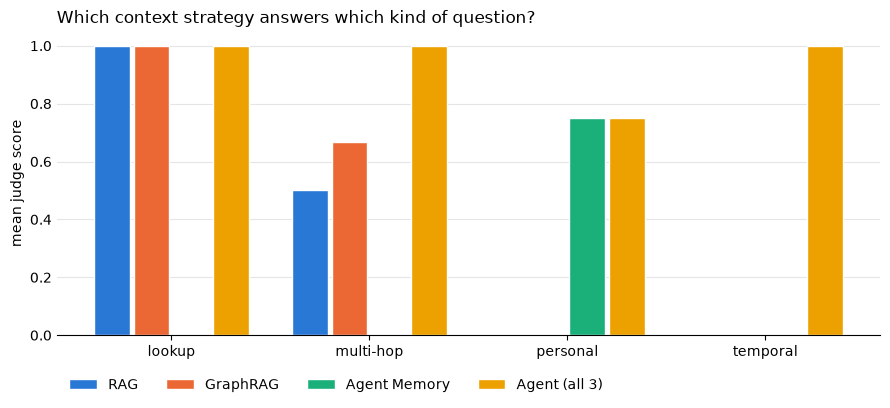

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# Categorical slots 1-4 of the validated default palette (fixed order, one colour per system)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
types = ["lookup", "multi-hop", "personal", "temporal"]
x = np.arange(len(types))
width = 0.2

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, system in enumerate(SYSTEMS):
    ax.bar(x + (i - 1.5) * width, summary.loc[types, system], width - 0.02,
           label=system, color=COLORS[i], edgecolor="white", linewidth=1)
ax.set_xticks(x, types)
ax.set_ylim(0, 1.05)
ax.set_ylabel("mean judge score")
ax.set_title("Which context strategy answers which kind of question?", loc="left", fontsize=12)
ax.yaxis.grid(True, color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.1))
plt.tight_layout()
plt.show()

In [36]:
# Drill into any disagreement
results.loc[results.verdict != "correct", ["system", "question", "answer", "verdict", "reason"]]

,system,question,answer,verdict,reason
2,Agent Memory,How long do I have to return electronics?,I don't know.,wrong,The answer states 'I don't know' instead of providing the 14-day return period.
6,Agent Memory,How quickly are refunds issued?,I don't know.,wrong,The answer provides no information and states 'I don't know'.
8,RAG,What did Lisa Chen do in Barcelona?,I don't know,wrong,The answer states I don't know despite the information being provided in the reference.
9,GraphRAG,What did Lisa Chen do in Barcelona?,"Based on the provided context, I don't know what Lisa Chen did in Barcelona (the conte...",wrong,The answer incorrectly claims it does not know what Lisa Chen did in Barcelona.
10,Agent Memory,What did Lisa Chen do in Barcelona?,I don't know.,wrong,The answer provides no information and claims not to know.
12,RAG,Which Acme people spoke at the event held in Barcelona?,"Based on the provided context, Marco Rossi spoke at the event.",partial,The answer mentions Marco Rossi but misses Lisa Chen.
14,Agent Memory,Which Acme people spoke at the event held in Barcelona?,I don't know,wrong,The answer states 'I don't know' instead of providing the names of the people from the...
18,Agent Memory,Who leads the team that built AcmeSearch?,I don't know.,wrong,The answer provides no information instead of identifying Lisa Chen.
20,RAG,What outdoor activities do I enjoy?,I don't know,wrong,The answer states I don't know instead of providing the outdoor activities.
21,GraphRAG,What outdoor activities do I enjoy?,I don't know,wrong,The answer states 'I don't know' despite the reference containing the information.


### When to use which

| | RAG | GraphRAG | Agent Memory (temporal KG) |
|---|---|---|---|
| **Asks** | What text is similar? | What facts are connected? | What did this user tell me, and is it still true? |
| **Great for** | FAQs, policies, docs: answers that live in one chunk | Multi-hop questions across documents, entity-centric analytics | Personalisation, continuity across sessions, facts that change over time |
| **Data** | Static corpus | Static corpus → entity graph | Stream of episodes (chats, events), per user |
| **Time-aware** | No | No | **Yes**: `valid_at`/`invalid_at` + `created_at`/`expired_at` |
| **Cost** | Cheapest: embed once | LLM extraction at build time; graph upkeep | LLM extraction on **every** write; incremental, no rebuild |
| **Fails when** | Answer is spread across docs | Question is about the user, or about *when* | Question is about the company corpus |

Many production systems end up combining all three, like the LangGraph agent above. Pick based on the question you need to answer, not the trend.

## 7. Cleanup

Uncomment to delete only this notebook's data from the shared AuraDB.

In [37]:
# clear_graphrag()
# cypher("DROP INDEX graphrag_chunks IF EXISTS"); cypher("DROP INDEX graphrag_entity_ids IF EXISTS")
# await clear_memory()
label_counts()

,label,nodes
0,__Entity__,20
1,Entity,13
2,Episodic,12
3,Document,8
4,Preference,4
5,Location,4
6,Organization,4
7,City,4
8,Event,3
9,Topic,3


In [38]:
await graphiti.close()
driver.close()
graph.close()